# Analisis operacional - RedConecta Telecom S. A.
**Proyecto de Ciencia de Datos - Semana 8**

Este notebook integra el flujo reproducible del proyecto: carga de datos,
evaluacion de calidad, analisis estadistico con NumPy/SciPy, visualizacion y
generacion de salidas por area. La logica reutilizable vive en el paquete
`src/` (codigo modular), por lo que aqui solo orquestamos y comentamos.

**Objetivo general:** analizar la informacion operacional para respaldar
decisiones orientadas a mejorar la calidad del servicio.

**Preguntas de investigacion**
1. Como se relacionan trafico, incidencias y carga de soporte con la calidad del servicio.
2. Que diferencias de desempeno existen entre regiones y tipos de servicio.
3. Que tan confiable es el dataset para sustentar decisiones.

In [1]:
import sys
from pathlib import Path

# Permite importar el paquete src/ al ejecutar el notebook desde notebooks/
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd

from src import calidad_datos, io_salidas, visualizacion
from src.estadistica import (
    resumen_descriptivo, intervalo_confianza_media,
    correlacion_pearson, prueba_t_dos_grupos,
)

pd.set_option("display.width", 120)
np.random.seed(42)
print("Entorno listo. Raiz del proyecto:", RAIZ)

Entorno listo. Raiz del proyecto: D:\IACC\CIENCIA_DE_DATOS\SEMANA_8\Evaluacion\proyecto


## 1. Carga y limpieza del dataset
La funcion `cargar_dataset` (en `src/io_salidas.py`) lee el Excel, normaliza texto y ordena por fecha. Joblib cachea el resultado.

In [2]:
ruta = RAIZ / "data" / "raw" / "dataset_set_D_telecomunicaciones.xlsx"
df = io_salidas.cargar_dataset(str(ruta))
print("Dimensiones:", df.shape)
df.head()

Dimensiones: (200, 10)


,fecha_registro,region,tipo_servicio,trafico_datos_gb,latencia_ms,incidencias_reportadas,tickets_soporte,tiempo_resolucion_hr,clientes_afectados,cumplimiento_sla
0,2025-03-01,Centro,Empresas,457.8,21.3,0,27,22.4,144,No cumple
1,2025-03-02,Norte,Internet Hogar,383.4,36.5,13,19,39.4,290,No cumple
2,2025-03-03,Norte,Empresas,457.3,97.4,7,15,1.7,427,Cumple
3,2025-03-04,Norte,Móvil,62.5,119.4,12,30,38.2,116,Cumple
4,2025-03-05,Norte,Empresas,356.1,111.0,9,30,21.5,389,No cumple


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   fecha_registro          200 non-null    datetime64[ns]
 1   region                  200 non-null    object        
 2   tipo_servicio           200 non-null    object        
 3   trafico_datos_gb        200 non-null    float64       
 4   latencia_ms             200 non-null    float64       
 5   incidencias_reportadas  200 non-null    int64         
 6   tickets_soporte         200 non-null    int64         
 7   tiempo_resolucion_hr    200 non-null    float64       
 8   clientes_afectados      200 non-null    int64         
 9   cumplimiento_sla        200 non-null    object        
dtypes: datetime64[ns](1), float64(3), int64(3), object(3)
memory usage: 15.8+ KB


## 2. Evaluacion de la calidad de los datos (Pregunta 5)
Se revisan completitud, duplicados, validez de rangos, categorias y atipicos.

In [4]:
calidad = calidad_datos.resumen_calidad(df)
print("Puntaje global de calidad:", calidad["puntaje_global"], "/ 100")
print("Duplicados:", calidad["duplicados"])
calidad["completitud"]

Puntaje global de calidad: 95.0 / 100
Duplicados: 0


,faltantes,pct_faltantes,pct_completitud
fecha_registro,0,0.0,100.0
region,0,0.0,100.0
tipo_servicio,0,0.0,100.0
trafico_datos_gb,0,0.0,100.0
latencia_ms,0,0.0,100.0
incidencias_reportadas,0,0.0,100.0
tickets_soporte,0,0.0,100.0
tiempo_resolucion_hr,0,0.0,100.0
clientes_afectados,0,0.0,100.0
cumplimiento_sla,0,0.0,100.0


In [5]:
calidad["validez_rangos"]

,columna,rango_esperado,fuera_de_rango
0,trafico_datos_gb,"[0, 2000]",0
1,latencia_ms,"[0, 1000]",0
2,incidencias_reportadas,"[0, 500]",0
3,tickets_soporte,"[0, 500]",0
4,tiempo_resolucion_hr,"[0, 240]",0
5,clientes_afectados,"[0, 100000]",0


In [6]:
calidad["atipicos"]

,columna,atipicos,pct_atipicos
0,trafico_datos_gb,0,0.0
1,latencia_ms,0,0.0
2,incidencias_reportadas,0,0.0
3,tickets_soporte,0,0.0
4,tiempo_resolucion_hr,0,0.0
5,clientes_afectados,0,0.0


**Lectura:** el dataset presenta 100% de completitud, sin duplicados ni
valores fuera de rango operativo. La ausencia total de datos faltantes y
atipicos sugiere que se trata de datos sinteticos/controlados: en un entorno
real conviene mantener estos chequeos porque datos de baja confiabilidad
(latencias negativas, categorias mal escritas, duplicados) llevarian a
dimensionar mal el soporte y a reportar un cumplimiento de SLA irreal.

## 3. Analisis estadistico (NumPy / SciPy)

In [7]:
desc = resumen_descriptivo(df["latencia_ms"].to_numpy())
pd.Series(desc)

n            200.000000
media         64.861500
mediana       64.900000
desv_std      32.907065
minimo        11.200000
maximo       119.900000
iqr           54.850000
asimetria      0.109655
curtosis      -1.252430
dtype: float64

In [8]:
ic = intervalo_confianza_media(df["latencia_ms"].to_numpy())
print(f"IC 95% latencia media: [{ic[0]:.2f}, {ic[1]:.2f}] ms")

corr1 = correlacion_pearson(df["trafico_datos_gb"].to_numpy(), df["latencia_ms"].to_numpy())
corr2 = correlacion_pearson(df["incidencias_reportadas"].to_numpy(), df["tickets_soporte"].to_numpy())
print(f"Trafico vs latencia:    r={corr1['r']:.3f} (p={corr1['p_valor']:.3f})")
print(f"Incidencias vs tickets: r={corr2['r']:.3f} (p={corr2['p_valor']:.3f})")

IC 95% latencia media: [60.27, 69.45] ms
Trafico vs latencia:    r=-0.077 (p=0.280)
Incidencias vs tickets: r=-0.075 (p=0.294)


In [9]:
cumple = df.loc[df.cumplimiento_sla == "Cumple", "tiempo_resolucion_hr"].to_numpy()
no_cumple = df.loc[df.cumplimiento_sla == "No cumple", "tiempo_resolucion_hr"].to_numpy()
prueba_t_dos_grupos(cumple, no_cumple)

{'t': -0.5585352891451735,
 'p_valor': 0.5771268471846512,
 'significativo_05': False}

**Lectura:** en este dataset las correlaciones son debiles y no
significativas, y la prueba t no detecta diferencia en el tiempo de resolucion
entre quienes cumplen y no cumplen SLA. Es un hallazgo valido: el analisis
reproducible permite **descartar** relaciones que a priori parecian evidentes y
orientar la mejora hacia otras variables (region, tipo de servicio).

## 4. Analisis por region y tipo de servicio

In [10]:
df.groupby("region")[["latencia_ms","incidencias_reportadas","tickets_soporte","clientes_afectados"]].mean().round(1)

,latencia_ms,incidencias_reportadas,tickets_soporte,clientes_afectados
region,,,,
Centro,68.1,12.7,31.7,271.7
Norte,64.6,13.0,30.5,268.6
Sur,61.8,14.9,31.9,255.8


In [11]:
(pd.crosstab(df.tipo_servicio, df.cumplimiento_sla, normalize="index")*100).round(1)

cumplimiento_sla,Cumple,No cumple
tipo_servicio,,
Empresas,48.4,51.6
Internet Hogar,46.8,53.2
Móvil,49.1,50.9


## 5. Visualizaciones y dashboard exploratorio

In [12]:
figuras = visualizacion.generar_todas_las_figuras(df, str(RAIZ / "outputs" / "figures"))
dash = visualizacion.construir_dashboard(df, figuras, str(RAIZ / "outputs" / "dashboard.html"))
print("Dashboard generado en:", dash)

Dashboard generado en: D:\IACC\CIENCIA_DE_DATOS\SEMANA_8\Evaluacion\proyecto\outputs\dashboard.html


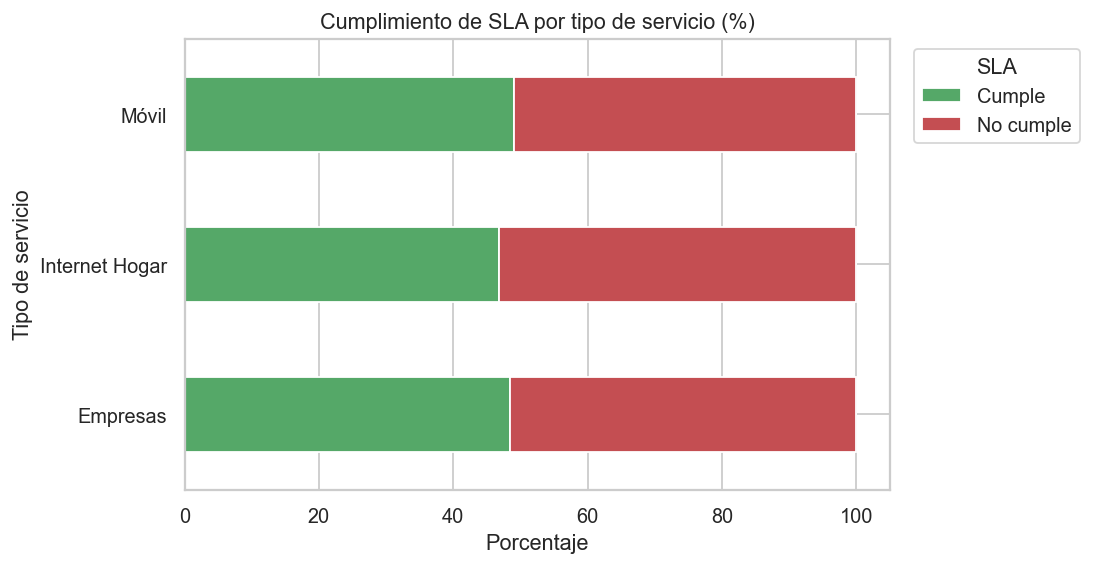

In [13]:
from IPython.display import Image
Image(filename=str(RAIZ / "outputs" / "figures" / "fig_sla_servicio.png"))

## 6. Archivos de salida por area

In [14]:
sop = io_salidas.salida_soporte_tecnico(df, str(RAIZ / "data" / "processed"))
exp = io_salidas.salida_experiencia_clientes(df, str(RAIZ / "data" / "processed"))
print("Soporte Tecnico:", sop.shape, "| Experiencia Clientes:", exp.shape)
sop.head()

Soporte Tecnico: (200, 7) | Experiencia Clientes: (200, 6)


,fecha_registro,region,tipo_servicio,incidencias_reportadas,tickets_soporte,tiempo_resolucion_hr,tickets_por_incidencia
0,2025-03-01,Centro,Empresas,0,27,22.4,NaN
1,2025-03-02,Norte,Internet Hogar,13,19,39.4,1.46
2,2025-03-03,Norte,Empresas,7,15,1.7,2.14
3,2025-03-04,Norte,Móvil,12,30,38.2,2.50
4,2025-03-05,Norte,Empresas,9,30,21.5,3.33


In [15]:
exp.head()

,fecha_registro,tipo_servicio,clientes_afectados,latencia_ms,cumplimiento_sla,nivel_latencia
0,2025-03-01,Empresas,144,21.3,No cumple,Buena
1,2025-03-02,Internet Hogar,290,36.5,No cumple,Buena
2,2025-03-03,Empresas,427,97.4,Cumple,Critica
3,2025-03-04,Móvil,116,119.4,Cumple,Critica
4,2025-03-05,Empresas,389,111.0,No cumple,Critica


## 7. Conclusiones
- El flujo es **reproducible**: cualquier equipo con `requirements.txt` obtiene
  los mismos resultados ejecutando `python main.py` o este notebook.
- El **codigo modular** (`src/`) con NumPy, SciPy y Joblib evita duplicar logica
  y acelera la re-ejecucion mediante cache.
- La **calidad del dataset** es alta (95/100), pero los chequeos quedan
  incorporados para proteger el analisis ante futuras cargas de datos reales.
- Las diferencias relevantes aparecen por **region y tipo de servicio**, insumo
  directo para priorizar recursos de soporte y mejorar la experiencia.